In [1]:
# import sys
# !{sys.executable} -m pip install "tabfm[pytorch]"

In [2]:
import os

os.environ.pop("HF_HUB_OFFLINE", None)
os.environ.pop("TRANSFORMERS_OFFLINE", None)

print("HF_HUB_OFFLINE =", os.environ.get("HF_HUB_OFFLINE"))

HF_HUB_OFFLINE = None


In [3]:
# %pip install tabfm
import os

os.environ.pop("HF_HUB_OFFLINE", None)
os.environ.pop("TRANSFORMERS_OFFLINE", None)
os.environ["HF_HUB_OFFLINE"] = "False"
os.environ["TRANSFORMERS_OFFLINE"] = "False"

from huggingface_hub import login
login()

In [4]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

import tabfm
from tabfm import TabFMClassifier, tabfm_v1_0_0_pytorch as tabfm_v1_0_0
print("TabFM imported successfully!")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (f1_score, accuracy_score, precision_score)
from sklearn.metrics import (recall_score, classification_report, confusion_matrix)

random_state = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

TabFM imported successfully!
Using device: cuda


/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# !pip install seaborn
# !pip install scikit-learn

In [6]:
training_data = pd.read_csv("../dataset/task1_static/train_features.csv")
training_labels = pd.read_csv("../dataset/task1_static/train_labels.csv")
training_data = training_data.merge(training_labels, left_on="flow_id", right_on="flow_id")

validation_data = pd.read_csv("../dataset/task1_static/validation_features.csv")
validation_labels = pd.read_csv("../dataset/task1_static/validation_labels.csv")
validation_data = validation_data.merge(validation_labels, left_on="flow_id", right_on="flow_id")

In [ ]:
selected_features = ['transport', 'start_rel', 'duration', 'server_port', 'packet_count_down', 'bytes_up', 'mean_pkt_size_up', 'mean_pkt_size_down',
                     'std_pkt_size_up', 'std_pkt_size_down', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'up_down_packet_ratio', 'up_down_byte_ratio']

low_association_features = ['std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat',
                            'std_iat', 'min_iat', 'max_iat', 'server_port']

# set(selected_features) - set(low_assoiation_features)
reduced_features = [f for f in selected_features if f not in low_association_features]

label_encoder = LabelEncoder()
y_full = label_encoder.fit_transform(training_data["app"])
y_val = label_encoder.transform(validation_data["app"])

n_classes = len(label_encoder.classes_)
print(f"Number of classes: {n_classes}")
if n_classes > 10:
    print("Warning: TabFM's classification checkpoint has a hard limit of 10 output "
          "classes. fit() will likely raise — group or drop some 'app' classes first.")

MAX_CONTEXT_ROWS = 10_000

if MAX_CONTEXT_ROWS is not None and len(training_data) > MAX_CONTEXT_ROWS:
    train_idx, _ = train_test_split(
        training_data.index, train_size=MAX_CONTEXT_ROWS,
        stratify=training_data["app"], random_state=random_state
    )
    training_data_sampled = training_data.loc[train_idx]
else:
    training_data_sampled = training_data

X_train = training_data_sampled[selected_features].copy()
y_train = label_encoder.transform(training_data_sampled["app"])
X_val = validation_data[selected_features].copy()

Number of classes: 6


#### Load the pretrained TabFM weights

In [8]:
# %pip install safetensors

In [9]:
tabfm_model = tabfm_v1_0_0.load(model_type="classification", device="cuda")

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1044.14it/s]


Loading weights from local directory


## Zero-shot evaluation helpers

In [10]:
def report_zero_shot(model, Xtr, ytr, Xte, yte, experiment_name):
    start = time.time()
    model.fit(Xtr, ytr)
    elapsed_fit = time.time() - start

    start = time.time()
    pred = model.predict(Xte)
    elapsed_pred = time.time() - start

    print("\n", experiment_name)
    print("Test macro-F1:", f1_score(yte, pred, average='macro'))
    print("Test accuracy:", accuracy_score(yte, pred))
    print(classification_report(yte, pred, zero_division=0))

    labels = np.unique(np.concatenate([yte, pred]))
    cm = confusion_matrix(yte, pred, labels=labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.inverse_transform(labels),
                yticklabels=label_encoder.inverse_transform(labels))
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion Matrix - {experiment_name}')
    plt.tight_layout(); plt.show()

    print(f"Fit time: {elapsed_fit:.2f}s | Predict time: {elapsed_pred:.2f}s")
    return model, pred, {"fit_s": elapsed_fit, "predict_s": elapsed_pred}

In [11]:
def run_experiment(model_name, feature_list):
    Xtr = X_train[feature_list].copy()
    Xte = X_val[feature_list].copy()
    clf = TabFMClassifier(model=tabfm_model)
    experiment_name = model_name + ('_E1_16features' if len(feature_list) == 16 else '_E2_reduced')
    return report_zero_shot(clf, Xtr, y_train, Xte, y_val, experiment_name)

### Experiment-1: All 16 selected features


 tabfm_E1_16features
Test macro-F1: 0.768575650928592
Test accuracy: 0.891566265060241
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.89      0.94      0.91        33
           2       1.00      1.00      1.00         5
           3       0.83      1.00      0.91        10
           4       0.94      0.94      0.94        18
           5       0.92      0.79      0.85        14

    accuracy                           0.89        83
   macro avg       0.76      0.78      0.77        83
weighted avg       0.87      0.89      0.88        83



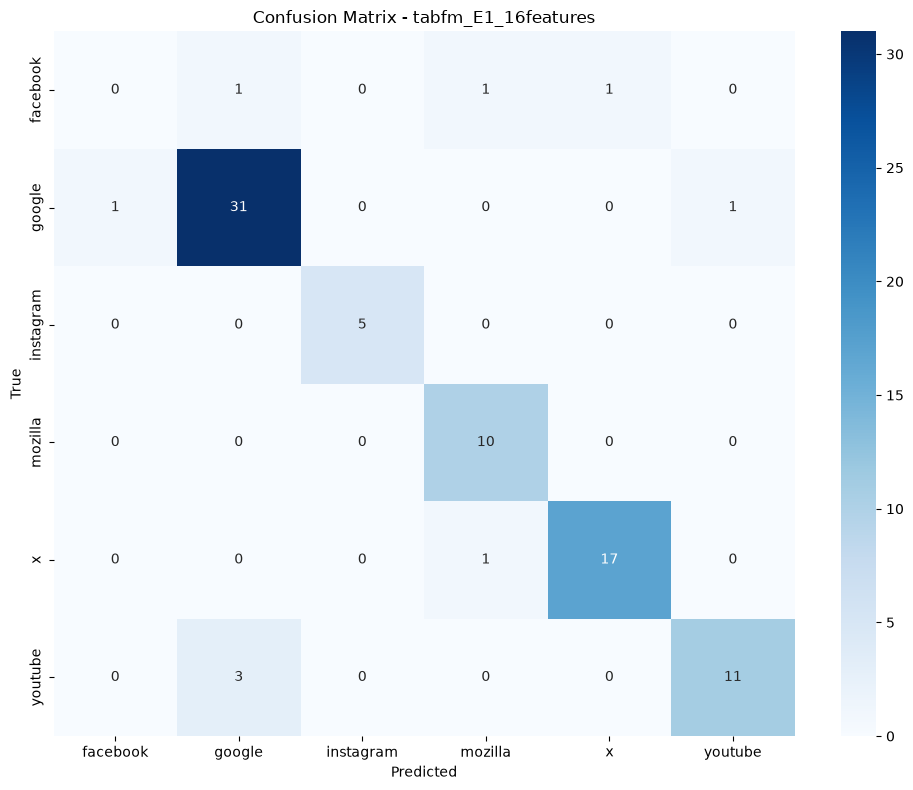

Fit time: 0.07s | Predict time: 1.48s


In [12]:
model_e1, pred_e1, timing_e1 = run_experiment('tabfm', selected_features)

### Experiment-2: Reduced feature set (9 features)


 tabfm_E2_reduced
Test macro-F1: 0.7342916232515551
Test accuracy: 0.8795180722891566
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.89      0.97      0.93        33
           2       1.00      0.80      0.89         5
           3       0.71      1.00      0.83        10
           4       1.00      0.89      0.94        18
           5       0.85      0.79      0.81        14

    accuracy                           0.88        83
   macro avg       0.74      0.74      0.73        83
weighted avg       0.86      0.88      0.86        83



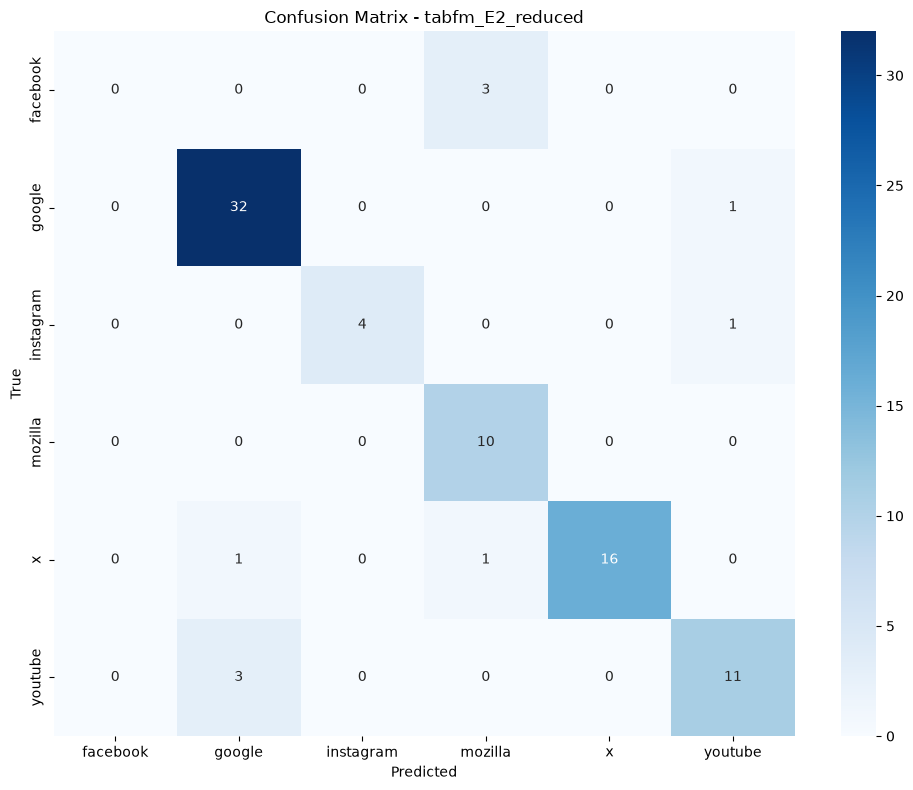

Fit time: 0.05s | Predict time: 1.29s


In [13]:
model_e2, pred_e2, timing_e2 = run_experiment('tabfm', reduced_features)

## Compare feature configurations

In [14]:
comparison = pd.DataFrame([
    {'Experiment': 'E1 - 16 features', 'Test_MacroF1': f1_score(y_val, pred_e1, average='macro'),
     'Test_Accuracy': accuracy_score(y_val, pred_e1),
     'Fit_s': timing_e1['fit_s'], 'Predict_s': timing_e1['predict_s']},
    {'Experiment': 'E2 - reduced features', 'Test_MacroF1': f1_score(y_val, pred_e2, average='macro'),
     'Test_Accuracy': accuracy_score(y_val, pred_e2),
     'Fit_s': timing_e2['fit_s'], 'Predict_s': timing_e2['predict_s']}
])
display(comparison)
comparison.to_csv('feature_ablation_comparison_tabfm.csv', index=False)

,Experiment,Test_MacroF1,Test_Accuracy,Fit_s,Predict_s
0,E1 - 16 features,0.768576,0.891566,0.065449,1.475432
1,E2 - reduced features,0.734292,0.879518,0.048145,1.291012


## Full metrics for the slides (balanced accuracy, weighted F1, AUC)

In [ ]:
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

rows = []
for name, model, feats in [('E1 - 16 features', model_e1, selected_features),
                           ('E2 - reduced features', model_e2, reduced_features)]:
    proba = model.predict_proba(X_val[feats])
    pred = proba.argmax(axis=1)
    rows.append({'Experiment': name,
                 'Accuracy': accuracy_score(y_val, pred),
                 'Balanced_Accuracy': balanced_accuracy_score(y_val, pred),
                 'F1_weighted': f1_score(y_val, pred, average='weighted'),
                 'Macro_F1': f1_score(y_val, pred, average='macro'),
                 'AUC_ROC': roc_auc_score(y_val, proba, multi_class='ovr')})
full_metrics = pd.DataFrame(rows)
display(full_metrics.round(4))
full_metrics.to_csv('feature_ablation_comparison_tabfm.csv', index=False)